# 07 — Uncapped LSTM (FD001)

Phase 1 summarised the last 10 cycles by hand. Here an **LSTM** reads the raw window (the last W cycles × 14 sensors) one cycle at a time and keeps a memory (cell state). Three gates decide what to forget, what to add and what to pass on, so it can notice a slow drift over 30 cycles that a 10-cycle summary misses.

**Uncapped** means the model is trained on the true RUL, so it can predict 200 or 300. This is the half of the final hybrid that answers for engines far from failure.

Everything is trained with the shared recipe in `src/train.py` (Adam, batch 128, MSE on RUL / 100, gradient clipping 1.0, LR halved on plateau, early stopping on 16 held-out training engines with the best weights restored). The models are in `src/models_lstm.py`.

All settings are chosen on **validation** (100 points: 22 early, 78 late). Test labels are not loaded here; test predictions are only written to `results/` for notebook 10.

In [1]:
import sys
sys.path.append("../src")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import train as T
from evaluation import CUTOFFS
from models_lstm import LSTMRegressor, CNNLSTM

SEEDS_EXP = [0, 1, 2]        # experiments
SEEDS_FINAL = [0, 1, 2, 3, 4]  # final model
RESULTS = "../results"

In [2]:
print("early-stopping engines:", [int(e) for e in T._data()["es_engines"]])
y_val = T.val_rul()
print("validation points:", len(y_val), " early (RUL > 125):", int((y_val > 125).sum()), " late:", int((y_val <= 125).sum()))

early-stopping engines: [2, 3, 6, 16, 23, 26, 40, 44, 51, 57, 58, 67, 71, 75, 88, 97]
validation points: 100  early (RUL > 125): 22  late: 78


## 1. Training curve

One run: W = 30, 2 layers × 64, seed 0. After every epoch the loss is measured on the 16 early-stopping engines. Training stops 15 epochs after the best one, and the weights from the best epoch are restored.

epochs run: 18, best epoch: 3, early-stopping loss at best: 0.1549
validation: {'mae': 24.58, 'rmse': 34.56, 'early_rmse': 56.56, 'late_rmse': 25.08}


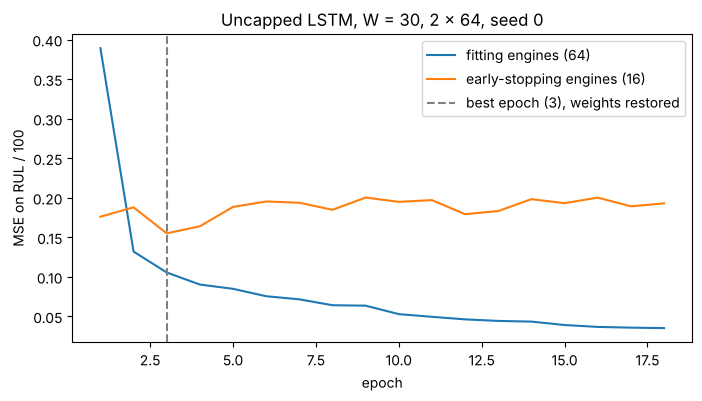

In [3]:
w = T.get_windows(30)
history = []
model, epochs = T.fit(lambda: LSTMRegressor(units=64, layers=2), w["X_fit"], w["y_fit"], w["X_es"], w["y_es"],
                      seed=0, history=history)
fit_loss, es_loss = np.array(history).T
best = int(np.argmin(es_loss)) + 1
print(f"epochs run: {epochs}, best epoch: {best}, early-stopping loss at best: {es_loss[best - 1]:.4f}")
print("validation:", {k: round(v, 2) for k, v in T.score_bands(y_val, T.predict(model, w["X_val"])).items()})

ep = np.arange(1, epochs + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ep, fit_loss, label="fitting engines (64)")
ax.plot(ep, es_loss, label="early-stopping engines (16)")
ax.axvline(best, color="grey", ls="--", label=f"best epoch ({best}), weights restored")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE on RUL / 100")
ax.set_title("Uncapped LSTM, W = 30, 2 × 64, seed 0")
ax.legend()
plt.show()

The fitting loss keeps falling, but the early-stopping loss stops improving after a few epochs and drifts up. From then on the model is learning the 64 fitting engines rather than engines in general. Early stopping keeps the weights from the best epoch. The best epoch differs by seed and setting, which is why the number of epochs is not fixed.

## 2. Window length (3 seeds, validation)

1 layer × 64, W = 30 / 50 / 70. Each seed is scored on its own; the table shows the mean over seeds and the spread (std) of RMSE.

In [4]:
exp_rows, cache, times = [], {}, {}

def experiment(name, make_model, W, cap=None, lr=1e-3):
    print(name)
    start = time.time()
    val_preds, _ = T.run_seeds(make_model, W, SEEDS_EXP, cap=cap, lr=lr)
    times[name] = (time.time() - start) / len(SEEDS_EXP)
    cache[name] = val_preds
    return T.summarise(val_preds, name)

window_rows = [experiment(f"W{W} 64x1", lambda: LSTMRegressor(units=64, layers=1), W) for W in (30, 50, 70)]
window = pd.DataFrame(window_rows)
window.to_csv(f"{RESULTS}/experiments_uncapped_window.csv", index=False)
window.round(2)

W30 64x1


  seed 0: 35 epochs, 21 s, val RMSE 35.79


  seed 1: 24 epochs, 15 s, val RMSE 39.05


  seed 2: 20 epochs, 12 s, val RMSE 34.94
W50 64x1


  seed 0: 17 epochs, 14 s, val RMSE 40.73


  seed 1: 19 epochs, 15 s, val RMSE 36.14


  seed 2: 20 epochs, 17 s, val RMSE 39.03
W70 64x1


  seed 0: 17 epochs, 25 s, val RMSE 39.63


  seed 1: 20 epochs, 29 s, val RMSE 33.55


  seed 2: 20 epochs, 30 s, val RMSE 42.90


,setting,rmse_mean,rmse_std,late_rmse_mean,late_rmse_std,early_rmse_mean
0,W30 64x1,36.59,1.77,21.84,1.20,66.27
1,W50 64x1,38.63,1.89,25.68,4.77,66.09
2,W70 64x1,38.69,3.87,25.14,4.17,67.44


## 3. Size (3 seeds, validation, W = 30)

32 / 64 / 128 units × 1 / 2 layers. The 64 × 1 row is the W = 30 run from section 2 (same seeds, same windows).

In [5]:
size_rows = []
for units in (32, 64, 128):
    for layers in (1, 2):
        name = f"W30 {units}x{layers}"
        if (units, layers) == (64, 1):
            row = dict(window_rows[0], setting=name)
            times[name] = times["W30 64x1"]
        else:
            row = experiment(name, lambda u=units, l=layers: LSTMRegressor(units=u, layers=l), 30)
        size_rows.append(row)
size = pd.DataFrame(size_rows)
size.to_csv(f"{RESULTS}/experiments_uncapped_size.csv", index=False)
size.assign(seconds_per_run=size["setting"].map(times)).round(2)

W30 32x1


  seed 0: 32 epochs, 12 s, val RMSE 37.19


  seed 1: 16 epochs, 6 s, val RMSE 42.14


  seed 2: 27 epochs, 10 s, val RMSE 33.73
W30 32x2


  seed 0: 18 epochs, 13 s, val RMSE 34.06


  seed 1: 21 epochs, 15 s, val RMSE 40.04


... (7 outputs left out)

  seed 0: 37 epochs, 135 s, val RMSE 41.75


  seed 1: 21 epochs, 77 s, val RMSE 29.68


  seed 2: 28 epochs, 106 s, val RMSE 34.59


,setting,rmse_mean,rmse_std,late_rmse_mean,late_rmse_std,early_rmse_mean,seconds_per_run
0,W30 32x1,37.69,3.45,26.01,5.90,62.94,9.09
1,W30 32x2,39.36,4.08,29.43,4.47,62.68,13.16
2,W30 64x1,36.59,1.77,21.84,1.20,66.27,16.09
3,W30 64x2,34.28,0.77,23.56,1.42,58.04,28.82
4,W30 128x1,38.34,2.91,24.85,2.47,66.87,41.38
5,W30 128x2,35.34,4.96,27.23,2.49,54.79,105.99


## 4. CNN-LSTM check (3 seeds, validation)

The idea from arXiv 2412.15998: a 1D convolution over time (14 sensors → 64 channels, kernel 5) before the LSTM, optionally with max pooling. We test the idea in both settings our final model uses:

- **uncapped**: W = 30, lr 0.001 (compare with the plain 2 × 64 LSTM above);
- **capped**: W = 70, targets capped at 125, lr 0.003 (compare with the plain capped LSTM's late RMSE, 12.11, from the shared tuning runs).

We don't quote the paper's numbers: its own table contradicts itself (MLP RMSE 4.51 with R² 0.52 vs the "best" CNN-LSTM at 13.34 with R² 0.86).

In [6]:
cnnlstm_setups = [
    ("uncapped W30 pooling",              lambda: CNNLSTM(pool=True),            30, None, 1e-3),
    ("uncapped W30 no pooling",           lambda: CNNLSTM(pool=False),           30, None, 1e-3),
    ("uncapped W30 pooling 2 LSTM layers", lambda: CNNLSTM(pool=True, layers=2), 30, None, 1e-3),
    ("capped W70 pooling",                lambda: CNNLSTM(pool=True),            70, 125, 3e-3),
    ("capped W70 no pooling",             lambda: CNNLSTM(pool=False),           70, 125, 3e-3),
    ("capped W70 pooling 2 LSTM layers",  lambda: CNNLSTM(pool=True, layers=2),  70, 125, 3e-3),
]
cnnlstm = pd.DataFrame([experiment(name, mk, W, cap, lr) for name, mk, W, cap, lr in cnnlstm_setups])
cnnlstm.to_csv(f"{RESULTS}/experiments_cnnlstm.csv", index=False)
plain = size.set_index("setting").loc["W30 64x2"]
print(f"plain uncapped LSTM (W30 2x64): RMSE {plain['rmse_mean']:.2f}, late RMSE {plain['late_rmse_mean']:.2f}")
cnnlstm.round(2)

uncapped W30 pooling


  seed 0: 48 epochs, 29 s, val RMSE 41.69


  seed 1: 22 epochs, 13 s, val RMSE 38.05


  seed 2: 17 epochs, 10 s, val RMSE 39.91
uncapped W30 no pooling


  seed 0: 18 epochs, 15 s, val RMSE 39.99


  seed 1: 18 epochs, 14 s, val RMSE 40.40


... (10 outputs left out)

  seed 0: 21 epochs, 42 s, val RMSE 39.47


  seed 1: 19 epochs, 38 s, val RMSE 39.37


  seed 2: 18 epochs, 37 s, val RMSE 39.64
plain uncapped LSTM (W30 2x64): RMSE 34.28, late RMSE 23.56


,setting,rmse_mean,rmse_std,late_rmse_mean,late_rmse_std,early_rmse_mean
0,uncapped W30 pooling,39.88,1.49,25.32,2.18,70.18
1,uncapped W30 no pooling,40.46,0.41,30.81,0.93,63.80
2,uncapped W30 pooling 2 LSTM layers,36.59,0.46,24.95,1.35,62.19
3,capped W70 pooling,39.48,0.39,12.82,1.33,80.59
4,capped W70 no pooling,39.80,0.15,14.49,1.68,80.29
5,capped W70 pooling 2 LSTM layers,39.49,0.11,12.34,0.40,80.93


## 5. Final model (5 seeds)

W = 30, 2 layers × 64, lr 0.001, uncapped. Five seeds; each seed's predictions are saved as one column, in cycles and not rounded:

- `results/val_predictions_lstm_uncapped.csv`: 100 rows in `validation_cutoffs.csv` order, `engine_id, cycle, seed_0 … seed_4`
- `results/test_predictions_lstm_uncapped.csv`: 100 rows sorted by `engine_id`, `engine_id, seed_0 … seed_4` (no labels)

In [7]:
val_preds, test_preds = T.run_seeds(lambda: LSTMRegressor(units=64, layers=2), 30, SEEDS_FINAL)
seed_cols = [f"seed_{s}" for s in SEEDS_FINAL]

val_out = CUTOFFS[["engine_id", "cycle"]].copy()
val_out[seed_cols] = val_preds.T
val_out.to_csv(f"{RESULTS}/val_predictions_lstm_uncapped.csv", index=False)

test_out = pd.DataFrame({"engine_id": T.test_engine_ids()})
test_out[seed_cols] = test_preds.T
test_out.to_csv(f"{RESULTS}/test_predictions_lstm_uncapped.csv", index=False)
print("written:", val_out.shape, test_out.shape)

  seed 0: 18 epochs, 25 s, val RMSE 34.56


  seed 1: 21 epochs, 28 s, val RMSE 33.23


  seed 2: 29 epochs, 38 s, val RMSE 35.06


  seed 3: 39 epochs, 52 s, val RMSE 41.23


  seed 4: 30 epochs, 40 s, val RMSE 37.30
written: (100, 7) (100, 6)


In [8]:
# Score each seed on validation, then report the mean over seeds and the spread of RMSE.
per_seed = pd.DataFrame([T.score_bands(y_val, p) for p in val_preds], index=seed_cols)
display(per_seed.round(2))
final = per_seed.mean()
print(f"5-seed mean: MAE {final['mae']:.2f}, RMSE {final['rmse']:.2f} ± {per_seed['rmse'].std(ddof=0):.2f}, "
      f"early RMSE {final['early_rmse']:.2f}, late RMSE {final['late_rmse']:.2f}")

,mae,rmse,early_rmse,late_rmse
seed_0,24.58,34.56,56.56,25.08
seed_1,22.09,33.23,57.93,21.66
seed_2,23.09,35.06,59.63,23.94
seed_3,24.41,41.23,73.50,25.62
seed_4,23.22,37.30,67.18,22.61


5-seed mean: MAE 23.48, RMSE 36.28 ± 2.81, early RMSE 62.96, late RMSE 23.78


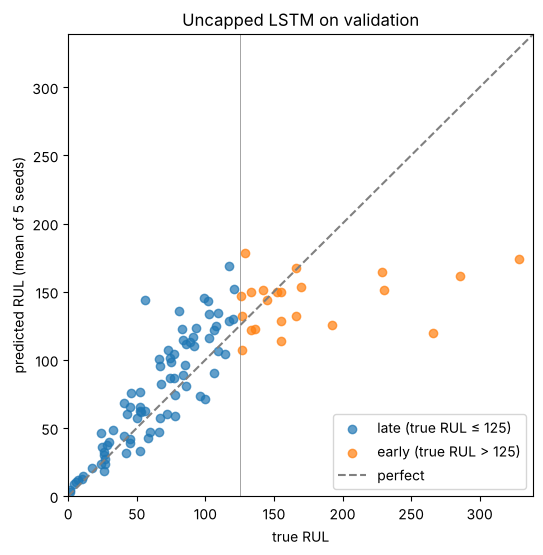

In [9]:
# Where the uncapped model is good and bad: predicted vs true RUL on validation (mean over the 5 seeds).
mean_pred = val_preds.mean(axis=0)
fig, ax = plt.subplots(figsize=(6, 6))
early = y_val > 125
ax.scatter(y_val[~early], mean_pred[~early], label="late (true RUL ≤ 125)", alpha=0.7)
ax.scatter(y_val[early], mean_pred[early], label="early (true RUL > 125)", alpha=0.7)
lim = [0, max(y_val.max(), mean_pred.max()) + 10]
ax.plot(lim, lim, color="grey", ls="--", label="perfect")
ax.axvline(125, color="grey", lw=0.5)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("true RUL"); ax.set_ylabel("predicted RUL (mean of 5 seeds)")
ax.set_title("Uncapped LSTM on validation")
ax.legend()
plt.show()

## 6. Findings

- **Best size: 2 layers × 64, window 30.** It has the lowest and most stable validation RMSE: 34.28 ± 0.77 over 3 seeds. W = 30 beats 50 and 70 (36.59 vs 38.63 / 38.69 at 1 × 64). Using 128 units was no better and took 1.4–3.7× longer per run (41 / 106 s vs 29 s). Using 32 units was unstable (± 3.5–4.1).
- **Seed spread is large.** The final 5 seeds range from 33.23 to 41.23 RMSE (36.28 ± 2.81). Almost all of it comes from the early points (early RMSE 56.6–73.5 per seed), while late RMSE stays at 21.7–25.6. A healthy engine with 200 or 300 cycles left looks much the same, so each seed guesses differently. That's why every number is a mean over seeds.
- **CNN-LSTM: no gain.** No version beat the plain LSTM. Uncapped, the best one (pooling + 2 LSTM layers) reached 36.59, against 34.28 for the plain 2 × 64. Capped, its late RMSE (12.34–14.49) did not beat the plain capped LSTM (12.11 in the shared tuning runs). Likely reason: the convolution squeezes the 14 sensors into 64 learned summaries before the LSTM sees them. That adds weights without adding information, and we only have 64 fitting engines.
- **Good far from failure, weak near it.** Early RMSE is 62.96, below every Phase 1 model (64.9–69.6), because the model is not held at 125: its predictions reach about 180. It still under-predicts engines with true RUL above 200 (scatter above), the limit of the data, not of the cap. Late RMSE is 23.78, about twice the capped LSTM's (12.16). So in the hybrid it only answers when the capped model already says the engine is healthy (prediction > 115).

**Reproduction check:** compared with the team's tuning runs, the final model (36.28 vs 36.47), 2 × 64 (34.28 vs 34.14) and W = 30 (36.59 vs 35.80) are within ±1. Some 3-seed settings land 2–3 RMSE away (W = 50, 128 × 2, CNN-LSTM with pooling). That is within the seed spread above, and no conclusion changes.